# Practical	work	n°6 : Introduction	to	Image	Processing	and	Analysis -Mathematical	Morphology-

### 1. Structuring Element

--- Rectangular Kernel ---
[[1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 ...
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]
 [1 1 1 ... 1 1 1]]

--- Circular/Elliptical Kernel ---
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]

--- Cross Kernel ---
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


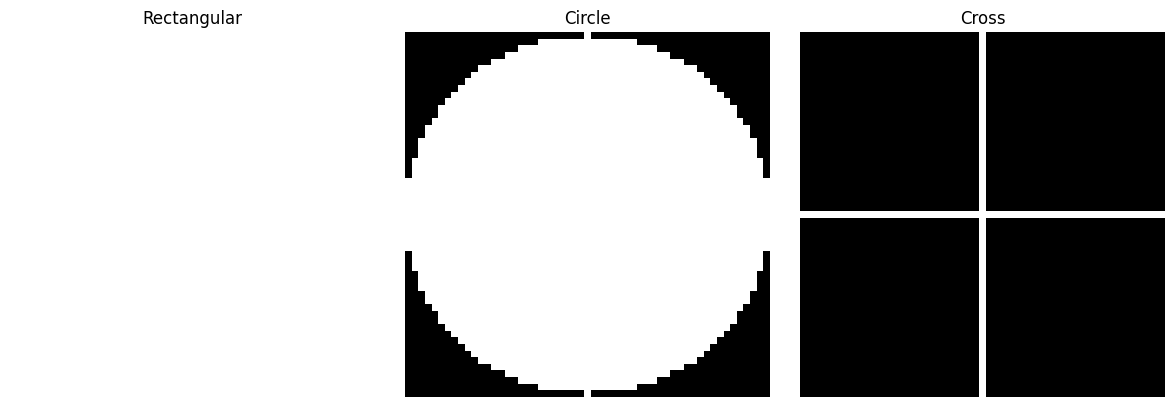

In [48]:
import cv2
import matplotlib.pyplot as plt

# Define the size of the structuring elements (e.g., 7x7 for better visibility)
kernel_size = (55, 55)

# Create the different masks/kernels
kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, kernel_size)
kernel_circle = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, kernel_size)
kernel_cross = cv2.getStructuringElement(cv2.MORPH_CROSS, kernel_size)

# Print the obtained kernels
print("--- Rectangular Kernel ---")
print(kernel_rect)
print("\n--- Circular/Elliptical Kernel ---")
print(kernel_circle)
print("\n--- Cross Kernel ---")
print(kernel_cross)

# Plot them using matplotlib
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# AJOUT DE vmin=0 ET vmax=1 ICI
axes[0].imshow(kernel_rect, cmap='gray', vmin=0, vmax=1) 
axes[0].set_title('Rectangular')
axes[0].axis('off')

# C'est une bonne pratique de l'ajouter partout pour être sûr :
axes[1].imshow(kernel_circle, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Circle')
axes[1].axis('off')

axes[2].imshow(kernel_cross, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Cross')
axes[2].axis('off')

plt.tight_layout()
plt.show()

### 2. Erosion and Dilatation

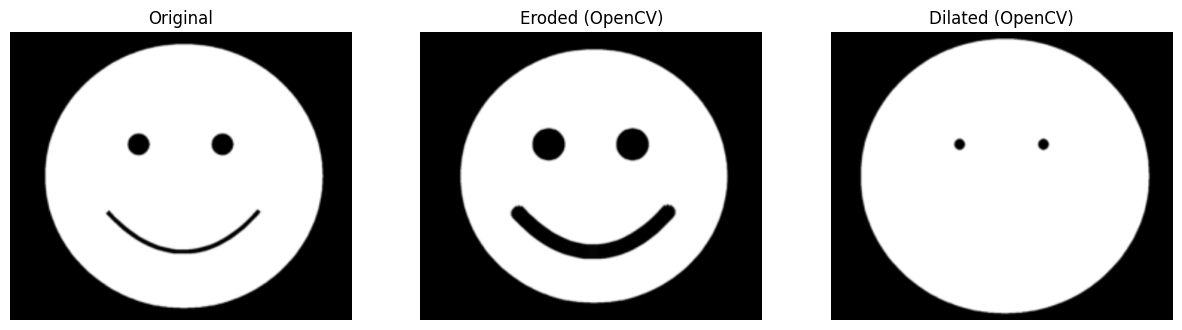

In [50]:
import cv2
import matplotlib.pyplot as plt

# 2.1 Load the image in grayscale
img_smiley = cv2.imread('smiley.png', cv2.IMREAD_GRAYSCALE)

# Create an elliptical structuring element of size 25x25
es_size = (15, 15)
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, es_size)

# 2.3 Apply Dilatation and Erosion using OpenCV built-in functions
dilated_cv2 = cv2.dilate(img_smiley, kernel_ellipse, iterations=1)
eroded_cv2 = cv2.erode(img_smiley, kernel_ellipse, iterations=1)

# Plotting the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_smiley, cmap='gray')
axes[0].set_title('Original')

axes[1].imshow(eroded_cv2, cmap='gray')
axes[1].set_title('Eroded (OpenCV)')

axes[2].imshow(dilated_cv2, cmap='gray')
axes[2].set_title('Dilated (OpenCV)')

for ax in axes:
    ax.axis('off')
plt.show()

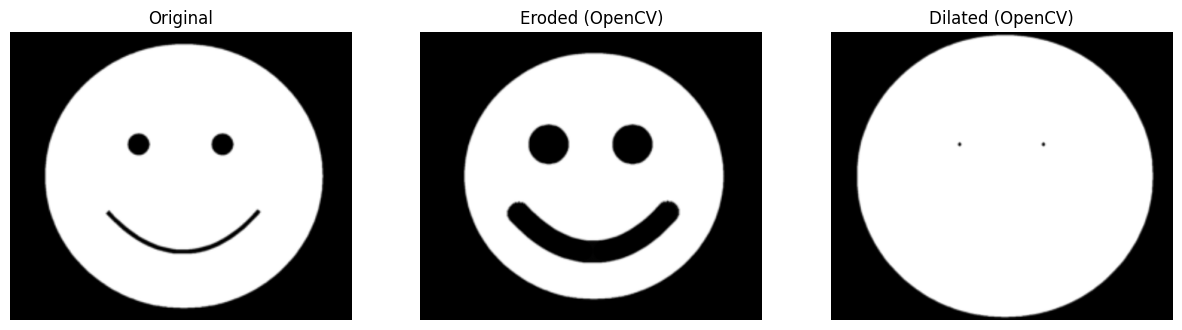

In [52]:
import cv2
import matplotlib.pyplot as plt

# 2.1 Load the image in grayscale
img_smiley = cv2.imread('smiley.png', cv2.IMREAD_GRAYSCALE)

# Create an elliptical structuring element of size 25x25
es_size = (25, 25)
kernel_ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, es_size)

# 2.3 Apply Dilatation and Erosion using OpenCV built-in functions
dilated_cv2 = cv2.dilate(img_smiley, kernel_ellipse, iterations=1)
eroded_cv2 = cv2.erode(img_smiley, kernel_ellipse, iterations=1)

# Plotting the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_smiley, cmap='gray')
axes[0].set_title('Original')

axes[1].imshow(eroded_cv2, cmap='gray')
axes[1].set_title('Eroded (OpenCV)')

axes[2].imshow(dilated_cv2, cmap='gray')
axes[2].set_title('Dilated (OpenCV)')

for ax in axes:
    ax.axis('off')
plt.show()

In [24]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# The wrapper function from your practical work
def morpho_convolution(image, ES, yourFunction):
    new_image = np.zeros(image.shape, np.uint8)
    for i in range(0, image.shape[0]):
        for j in range(0, image.shape[1]):
            # Fixed the variable name to match the function parameter
            new_image[i, j] = yourFunction(image, i, j, ES) 
    return new_image

# ---------------------------------------------------------
# 1. Custom Erosion Operator
# ---------------------------------------------------------
def my_erosion(image, i, j, ES):
    """
    Finds the minimum pixel value in the neighborhood defined by the ES.
    """
    k_h, k_w = ES.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    
    # Safely define the boundaries of our Region of Interest (ROI) to avoid IndexError at the image borders
    i_start = max(0, i - pad_h)
    i_end = min(image.shape[0], i + pad_h + 1)
    j_start = max(0, j - pad_w)
    j_end = min(image.shape[1], j + pad_w + 1)
    
    # Extract the neighborhood from the image
    neighborhood = image[i_start:i_end, j_start:j_end]
    
    # Align the Structuring Element to handle edges correctly
    es_i_start = pad_h - (i - i_start)
    es_i_end = pad_h + (i_end - i)
    es_j_start = pad_w - (j - j_start)
    es_j_end = pad_w + (j_end - j)
    es_valid = ES[es_i_start:es_i_end, es_j_start:es_j_end]
    
    # Keep only the pixels in the neighborhood where the Structuring Element is 1
    valid_pixels = neighborhood[es_valid == 1]
    
    if len(valid_pixels) > 0:
        return np.min(valid_pixels) # EROSION = Minimum value
    return 0

# ---------------------------------------------------------
# 2. Custom Dilatation Operator
# ---------------------------------------------------------
def my_dilatation(image, i, j, ES):
    """
    Finds the maximum pixel value in the neighborhood defined by the ES.
    """
    k_h, k_w = ES.shape
    pad_h, pad_w = k_h // 2, k_w // 2
    
    # Safely define boundaries
    i_start = max(0, i - pad_h)
    i_end = min(image.shape[0], i + pad_h + 1)
    j_start = max(0, j - pad_w)
    j_end = min(image.shape[1], j + pad_w + 1)
    
    neighborhood = image[i_start:i_end, j_start:j_end]
    
    # Align the Structuring Element
    es_i_start = pad_h - (i - i_start)
    es_i_end = pad_h + (i_end - i)
    es_j_start = pad_w - (j - j_start)
    es_j_end = pad_w + (j_end - j)
    es_valid = ES[es_i_start:es_i_end, es_j_start:es_j_end]
    
    valid_pixels = neighborhood[es_valid == 1]
    
    if len(valid_pixels) > 0:
        return np.max(valid_pixels) # DILATATION = Maximum value
    return 0

Processing Erosion...
Processing Dilatation...


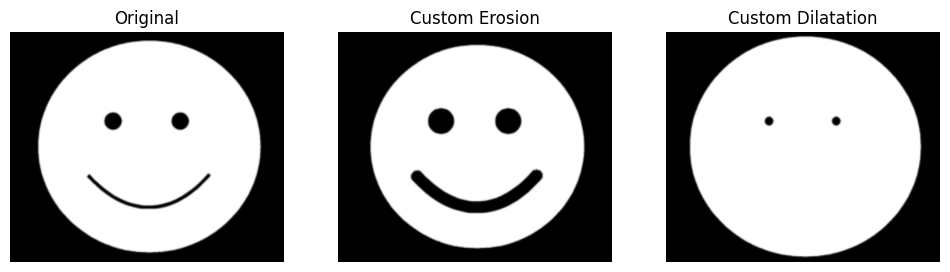

In [54]:
# Load the image
img_smiley = cv2.imread('smiley.png', cv2.IMREAD_GRAYSCALE)

# Create a small structuring element to test (e.g., 5x5 ellipse)
small_es = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

# Run the convolution with your custom operators
print("Processing Erosion...")
custom_eroded_img = morpho_convolution(img_smiley, small_es, my_erosion)

print("Processing Dilatation...")
custom_dilated_img = morpho_convolution(img_smiley, small_es, my_dilatation)

# Plot the results
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_smiley, cmap='gray'); axes[0].set_title('Original')
axes[1].imshow(custom_eroded_img, cmap='gray'); axes[1].set_title('Custom Erosion')
axes[2].imshow(custom_dilated_img, cmap='gray'); axes[2].set_title('Custom Dilatation')
for ax in axes: ax.axis('off')
plt.show()

### 3. Contour extraction-based mathematical morphology

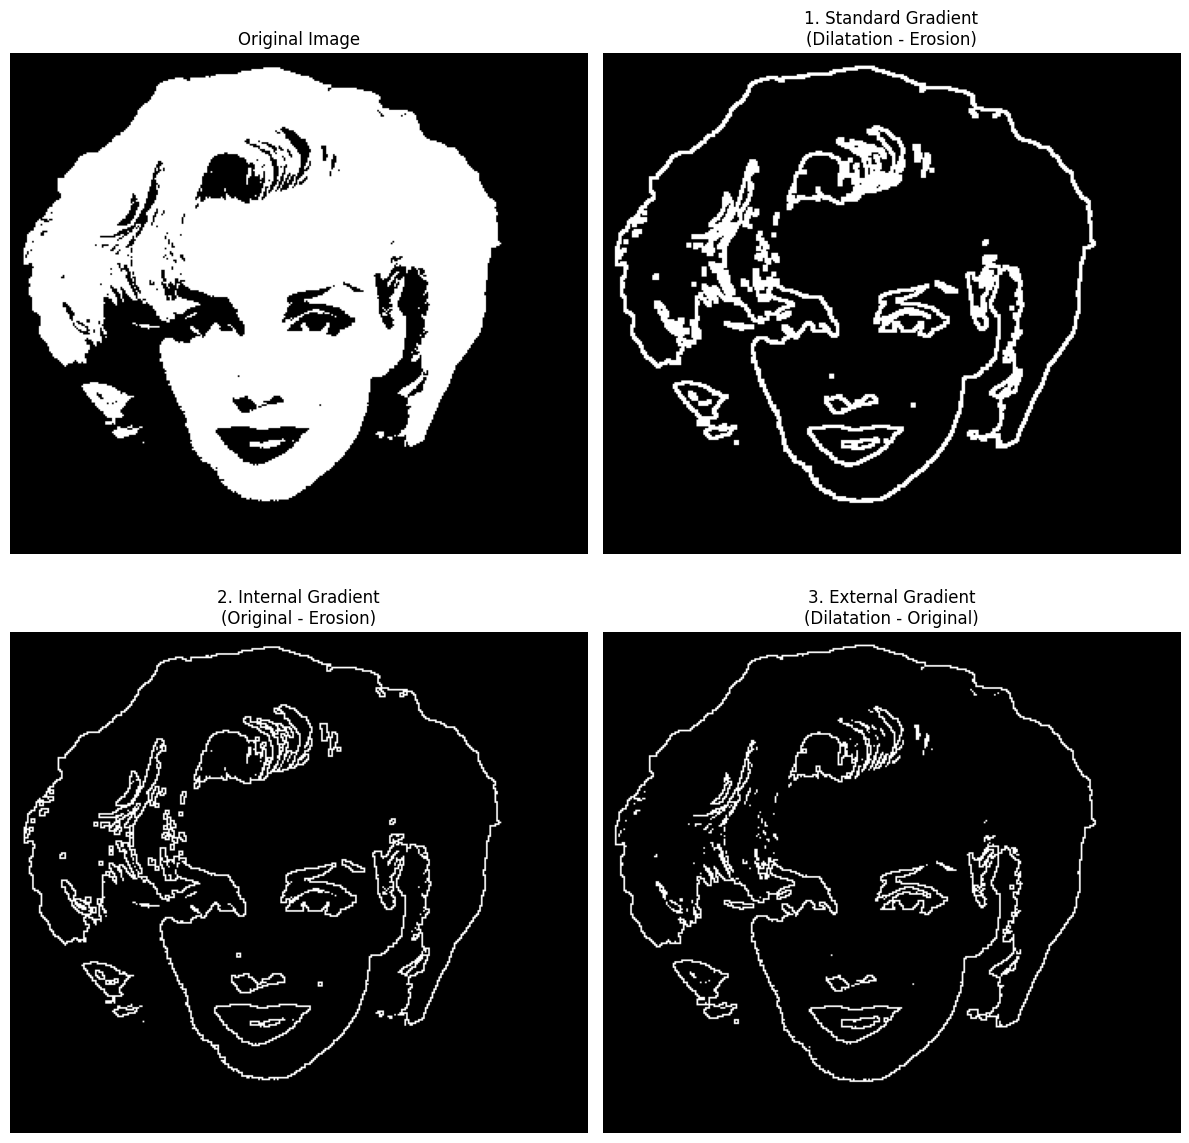

In [7]:
import cv2
import matplotlib.pyplot as plt

# 3.1 Load the image
img_marilyn = cv2.imread('mm-binary.png', cv2.IMREAD_GRAYSCALE)

# Define a Structuring Element (a 3x3 rectangular kernel is standard for thin contours)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Calculate Erosion and Dilatation
eroded = cv2.erode(img_marilyn, kernel, iterations=1)
dilated = cv2.dilate(img_marilyn, kernel, iterations=1)

# Calculate the three types of contours (gradients)
# Note: cv2.subtract prevents underflow issues (pixels dropping below 0) compared to basic numpy subtraction
gradient_standard = cv2.subtract(dilated, eroded)
gradient_internal = cv2.subtract(img_marilyn, eroded)
gradient_external = cv2.subtract(dilated, img_marilyn)

# Alternatively, OpenCV has a built-in for the standard gradient:
# gradient_standard_cv2 = cv2.morphologyEx(img_marilyn, cv2.MORPH_GRADIENT, kernel)

# Plotting the results
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

axes[0, 0].imshow(img_marilyn, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(gradient_standard, cmap='gray')
axes[0, 1].set_title('1. Standard Gradient\n(Dilatation - Erosion)')
axes[0, 1].axis('off')

axes[1, 0].imshow(gradient_internal, cmap='gray')
axes[1, 0].set_title('2. Internal Gradient\n(Original - Erosion)')
axes[1, 0].axis('off')

axes[1, 1].imshow(gradient_external, cmap='gray')
axes[1, 1].set_title('3. External Gradient\n(Dilatation - Original)')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()